# Exploración y preparación del dataset ICES-DATRAS

## Proyecto: Clasificación de registros de bacalao del Atlántico

Este notebook tiene como objetivo explorar y preparar los datos de la campaña científica NS-IBTS, correspondientes al primer trimestre de los años 2020 a 2025. El análisis busca identificar características geográficas y operativas de los lances que podrían relacionarse con la presencia registrada de bacalao del Atlántico y contribuir al estudio de sus patrones de distribución espacial.

Se analizarán las características del conjunto de datos, los tipos de registros, los valores faltantes y las variables disponibles para desarrollar posteriormente modelos de clasificación supervisada.

El análisis también permitirá identificar los lances válidos y establecer los criterios necesarios para construir una variable objetivo binaria, diferenciando los lances con registros de bacalao del Atlántico de aquellos sin registros de la especie.

In [1]:
import pandas as pd
from pathlib import Path

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


In [5]:
ruta_csv = Path("../data/raw/datras_ns_ibts_2020_2025_original.csv")

print("¿Existe el archivo?", ruta_csv.exists())
print("Ubicación:", ruta_csv.resolve())

¿Existe el archivo? True
Ubicación: C:\Users\veneg\Documents\Proyectos\clasificacion-bacalao-atlantico\data\raw\datras_ns_ibts_2020_2025_original.csv


In [6]:
from collections import Counter

conteo_registros = Counter()

with open(ruta_csv, "r", encoding="utf-8-sig") as archivo:
    for linea in archivo:
        tipo = linea.split(",")[0].strip()
        conteo_registros[tipo] += 1

print("Tipos de registros encontrados:")
for tipo, cantidad in conteo_registros.items():
    print(f"{tipo}: {cantidad}")

Tipos de registros encontrados:
RecordType: 2
HH: 2034
HL: 134934


### Identificación de los tipos de registros

El archivo original de ICES-DATRAS contiene dos tipos de registros:

- **HH (Haul Header):** 2.034 registros correspondientes a la información de los lances de investigación pesquera.
- **HL (Haul Length):** 134.934 registros biológicos asociados a las especies registradas durante los muestreos.

Además, se identificaron dos filas de encabezado que permiten distinguir la estructura de ambas secciones.

Esta organización requiere analizar las tablas por separado y posteriormente relacionarlas mediante los identificadores de los lances.

Para construir el conjunto de datos de clasificación, se buscará conservar una observación por lance, verificando previamente su validez y los criterios de registro de la especie estudiada.

In [12]:
import csv

registros_hh = []
registros_hl = []
encabezados_hh = None
encabezados_hl = None

with open(ruta_csv, "r", encoding="utf-8-sig", newline="") as archivo:
    lector = csv.reader(archivo)

    for fila in lector:
        if not fila:
            continue

        if fila[0] == "RecordType":
            if "HaulDur" in fila:
                encabezados_hh = fila
            elif "ScientificName_WoRMS" in fila:
                encabezados_hl = fila

        elif fila[0] == "HH":
            registros_hh.append(fila)

        elif fila[0] == "HL":
            registros_hl.append(fila)

df_hh = pd.DataFrame(registros_hh, columns=encabezados_hh)
df_hl = pd.DataFrame(registros_hl, columns=encabezados_hl)

print("Tabla HH:", df_hh.shape)
print("Tabla HL:", df_hl.shape)

Tabla HH: (2034, 71)
Tabla HL: (134934, 30)


In [8]:
display(df_hh.head())
display(df_hl.head())

,RecordType,Survey,Quarter,Country,Ship,Gear,SweepLngt,GearEx,DoorType,StNo,...,SecchiDepth,Turbidity,TidePhase,TideSpeed,PelSampType,MinTrawlDepth,MaxTrawlDepth,SurveyIndexArea,ReasonHaulDisruption,DateofCalculation
0,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,6,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625
1,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,8,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625
2,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,10,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625
3,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,11,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625
4,HH,NS-IBTS,1,DK,26D4,GOV,60,-9,P,19,...,-9,-9,-9,-9,-9,-9,-9,-9,-9,20260625


,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
0,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,250,4.00,-9,-9,126438,Merlangius merlangus,20260625
1,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,260,4.00,-9,-9,126438,Merlangius merlangus,20260625
2,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,270,8.00,-9,-9,126438,Merlangius merlangus,20260625
3,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,280,4.00,-9,-9,126438,Merlangius merlangus,20260625
4,HL,NS-IBTS,1,FR,35HT,GOV,50,-9,P,Y0021,...,-9,24480,.,290,14.00,-9,-9,126438,Merlangius merlangus,20260625


In [9]:
print("COLUMNAS DE LA TABLA HH:")
print(df_hh.columns.tolist())

print("\nCOLUMNAS DE LA TABLA HL:")
print(df_hl.columns.tolist())

COLUMNAS DE LA TABLA HH:
['RecordType', 'Survey', 'Quarter', 'Country', 'Ship', 'Gear', 'SweepLngt', 'GearEx', 'DoorType', 'StNo', 'HaulNo', 'Year', 'Month', 'Day', 'TimeShot', 'DepthStratum', 'HaulDur', 'DayNight', 'ShootLat', 'ShootLong', 'HaulLat', 'HaulLong', 'StatRec', 'Depth', 'HaulVal', 'HydroStNo', 'StdSpecRecCode', 'BySpecRecCode', 'DataType', 'Netopening', 'Rigging', 'Tickler', 'Distance', 'Warplngt', 'Warpdia', 'WarpDen', 'DoorSurface', 'DoorWgt', 'DoorSpread', 'WingSpread', 'Buoyancy', 'KiteDim', 'WgtGroundRope', 'TowDir', 'GroundSpeed', 'SpeedWater', 'SurCurDir', 'SurCurSpeed', 'BotCurDir', 'BotCurSpeed', 'WindDir', 'WindSpeed', 'SwellDir', 'SwellHeight', 'SurTemp', 'BotTemp', 'SurSal', 'BotSal', 'ThermoCline', 'ThClineDepth', 'CodendMesh', 'SecchiDepth', 'Turbidity', 'TidePhase', 'TideSpeed', 'PelSampType', 'MinTrawlDepth', 'MaxTrawlDepth', 'SurveyIndexArea', 'ReasonHaulDisruption', 'DateofCalculation']

COLUMNAS DE LA TABLA HL:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 

In [10]:
with open(ruta_csv, "r", encoding="utf-8-sig") as archivo:
    for linea in archivo:
        if linea.startswith("RecordType") and "HaulDur" not in linea:
            print(linea.strip())
            break

RecordType,Survey,Quarter,Country,Ship,Gear,SweepLngt,GearEx,DoorType,StNo,HaulNo,Year,SpecCodeType,SpecCode,SpecVal,Sex,TotalNo,CatIdentifier,NoMeas,SubFactor,SubWgt,CatCatchWgt,LngtCode,LngtClass,HLNoAtLngt,DevStage,LenMeasType,ValidAphiaID,ScientificName_WoRMS,DateofCalculation


In [13]:
print("Columnas de la tabla HL:")
print(df_hl.columns.tolist())

Columnas de la tabla HL:
['RecordType', 'Survey', 'Quarter', 'Country', 'Ship', 'Gear', 'SweepLngt', 'GearEx', 'DoorType', 'StNo', 'HaulNo', 'Year', 'SpecCodeType', 'SpecCode', 'SpecVal', 'Sex', 'TotalNo', 'CatIdentifier', 'NoMeas', 'SubFactor', 'SubWgt', 'CatCatchWgt', 'LngtCode', 'LngtClass', 'HLNoAtLngt', 'DevStage', 'LenMeasType', 'ValidAphiaID', 'ScientificName_WoRMS', 'DateofCalculation']


In [14]:
# Seleccionar los registros de bacalao del Atlántico
df_bacalao = df_hl[
    df_hl["ScientificName_WoRMS"] == "Gadus morhua"
].copy()

print("Registros biológicos totales:", len(df_hl))
print("Registros de Gadus morhua:", len(df_bacalao))

display(df_bacalao[
    ["Year", "Country", "Ship", "HaulNo",
     "ScientificName_WoRMS", "LngtClass", "HLNoAtLngt"]
].head(10))

Registros biológicos totales: 134934
Registros de Gadus morhua: 7557


,Year,Country,Ship,HaulNo,ScientificName_WoRMS,LngtClass,HLNoAtLngt
15,2020,FR,35HT,6,Gadus morhua,460,2.00
126,2020,GB-SCT,748S,41,Gadus morhua,330,1.00
127,2020,GB-SCT,748S,41,Gadus morhua,850,1.00
128,2020,GB-SCT,748S,41,Gadus morhua,1000,1.00
187,2020,GB-SCT,748S,43,Gadus morhua,270,1.00
188,2020,GB-SCT,748S,43,Gadus morhua,310,1.00
243,2020,GB-SCT,748S,44,Gadus morhua,310,1.00
244,2020,GB-SCT,748S,44,Gadus morhua,360,1.00
245,2020,GB-SCT,748S,44,Gadus morhua,650,1.00
282,2020,GB-SCT,748S,40,Gadus morhua,320,2.00


In [15]:
# Columnas propuestas para identificar cada lance
columnas_id = [
    "Survey", "Quarter", "Year",
    "Country", "Ship", "Gear", "HaulNo", "StNo"
]

# Contar combinaciones únicas entre los registros de bacalao
lances_bacalao = df_bacalao[columnas_id].drop_duplicates()

print("Registros biológicos de bacalao:", len(df_bacalao))
print("Combinaciones únicas de lance con bacalao:", len(lances_bacalao))

Registros biológicos de bacalao: 7557
Combinaciones únicas de lance con bacalao: 1354


In [16]:
# Verificar la identificación única de los lances en HH

total_hh = len(df_hh)
lances_unicos_hh = df_hh[columnas_id].drop_duplicates().shape[0]
duplicados_hh = df_hh.duplicated(subset=columnas_id).sum()

print("Total de registros HH:", total_hh)
print("Lances únicos identificados:", lances_unicos_hh)
print("Registros duplicados según el identificador:", duplicados_hh)

Total de registros HH: 2034
Lances únicos identificados: 2034
Registros duplicados según el identificador: 0


In [17]:
# Verificar que los lances con bacalao existan en la tabla HH

verificacion = lances_bacalao.merge(
    df_hh[columnas_id],
    on=columnas_id,
    how="left",
    indicator=True
)

print("Lances con bacalao identificados:", len(verificacion))

print("\nCorrespondencia con la tabla HH:")
print(verificacion["_merge"].value_counts())

Lances con bacalao identificados: 1354

Correspondencia con la tabla HH:
_merge
both          1354
left_only        0
right_only       0
Name: count, dtype: int64


In [18]:
print("Distribución de códigos de validez:")
print(df_hh["HaulVal"].value_counts(dropna=False))

print("\nRegistros de bacalao según código de validez:")

verificacion_validez = verificacion.merge(
    df_hh[columnas_id + ["HaulVal"]],
    on=columnas_id,
    how="left"
)

print(verificacion_validez["HaulVal"].value_counts(dropna=False))

Distribución de códigos de validez:
HaulVal
V    1970
I      57
A       7
Name: count, dtype: int64

Registros de bacalao según código de validez:
HaulVal
V    1335
I      15
A       4
Name: count, dtype: int64


### Evaluación de la validez de los lances

Se identificaron 1.970 lances válidos (V), 57 inválidos (I) y 7 estaciones adicionales válidas (A), según la codificación oficial de ICES-DATRAS.

Para el análisis inicial se seleccionarán los lances con código V, excluyendo los inválidos y dejando las estaciones adicionales para una evaluación posterior.

Entre los lances válidos, 1.335 presentan registros de bacalao del Atlántico y 635 no presentan registros de la especie en la tabla biológica. Estos últimos todavía no se consideran definitivamente negativos, ya que es necesario comprobar la integridad de la información del muestreo.

Fuente: ICES – Reference Codes, TS_HaulVal.

In [19]:
# Seleccionar los lances válidos
df_validos = df_hh[df_hh["HaulVal"] == "V"].copy()

# Identificar los lances con información biológica
lances_hl = df_hl[columnas_id].drop_duplicates()

# Comprobar la correspondencia
control_biologico = df_validos.merge(
    lances_hl,
    on=columnas_id,
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("Total de lances válidos:", len(df_validos))

print("\nCorrespondencia con los registros biológicos:")
print(control_biologico["_merge"].value_counts())

Total de lances válidos: 1970

Correspondencia con los registros biológicos:
_merge
both          1970
left_only        0
right_only       0
Name: count, dtype: int64


### Verificación de la información biológica

Se comprobó que los 1.970 lances clasificados como válidos
(código V) tienen registros asociados en la tabla biológica HL.

De ellos, 1.335 presentan registros de bacalao del Atlántico
(Gadus morhua), mientras que 635 no presentan registros de
la especie.

Esta correspondencia permite avanzar en la construcción de
la variable objetivo binaria. Sin embargo, antes de asignar
definitivamente la clase 0, se deberán verificar los criterios
de registro y la integridad de la información biológica.

In [20]:
# Revisar los códigos de registro de especies
# en los lances válidos

print("Códigos de especies estándar:")
print(df_validos["StdSpecRecCode"].value_counts(dropna=False))

print("\nCódigos de especies acompañantes:")
print(df_validos["BySpecRecCode"].value_counts(dropna=False))

print("\nCombinaciones de ambos códigos:")
display(
    df_validos.groupby(
        ["StdSpecRecCode", "BySpecRecCode"]
    ).size().reset_index(name="Cantidad de lances")
)

Códigos de especies estándar:
StdSpecRecCode
1    1970
Name: count, dtype: int64

Códigos de especies acompañantes:
BySpecRecCode
1    1970
Name: count, dtype: int64

Combinaciones de ambos códigos:


,StdSpecRecCode,BySpecRecCode,Cantidad de lances
0,1,1,1970


In [21]:
print("Códigos SpecVal de todos los registros biológicos:")
print(df_hl["SpecVal"].value_counts(dropna=False))

print("\nCódigos SpecVal de Gadus morhua:")
print(df_bacalao["SpecVal"].value_counts(dropna=False))

print("\nCódigos y cantidad de lances con bacalao:")
display(
    df_bacalao.groupby("SpecVal")[columnas_id]
    .apply(lambda x: x.drop_duplicates().shape[0])
    .reset_index(name="Cantidad de lances")
)

Códigos SpecVal de todos los registros biológicos:
SpecVal
1     134077
0        811
10        44
6          2
Name: count, dtype: int64

Códigos SpecVal de Gadus morhua:
SpecVal
1    7477
0      80
Name: count, dtype: int64

Códigos y cantidad de lances con bacalao:


,SpecVal,Cantidad de lances
0,0,15
1,1,1339


In [22]:
# Identificar combinaciones de lance y validez de bacalao
validez_bacalao = df_bacalao[
    columnas_id + ["SpecVal"]
].drop_duplicates()

# Incorporar la validez del lance desde HH
cruce_validez = validez_bacalao.merge(
    df_hh[columnas_id + ["HaulVal"]],
    on=columnas_id,
    how="left",
    validate="many_to_one"
)

# Resumen de ambas condiciones
tabla_validez = pd.crosstab(
    cruce_validez["HaulVal"],
    cruce_validez["SpecVal"]
)

display(tabla_validez)

SpecVal,0,1
HaulVal,,
A,0,4
I,15,0
V,0,1335


### Verificación cruzada de la validez de los registros

Se compararon los códigos de validez de los lances
(HaulVal) con los códigos de validez de los registros
biológicos de bacalao (SpecVal).

Se comprobó que los 1.335 lances válidos con registros
de Gadus morhua presentan información biológica válida.

Los registros restantes de bacalao corresponden a
15 lances inválidos y 4 estaciones adicionales.

Para construir el conjunto de datos de clasificación
se trabajará inicialmente con los 1.970 lances válidos.

De estos, 1.335 tienen registros válidos de bacalao
y 635 no presentan registros de la especie.

La ausencia de registros se interpretará únicamente
como ausencia de detección documentada durante el lance,
sin asumir que la especie está ausente de la zona.

In [23]:
# Identificar lances válidos sin registros de bacalao
lances_sin_bacalao = df_validos[columnas_id].merge(
    lances_bacalao,
    on=columnas_id,
    how="left",
    indicator=True
)

lances_sin_bacalao = lances_sin_bacalao[
    lances_sin_bacalao["_merge"] == "left_only"
][columnas_id].copy()

# Obtener sus registros biológicos
hl_sin_bacalao = df_hl.merge(
    lances_sin_bacalao,
    on=columnas_id,
    how="inner"
)

print("Lances válidos sin registros de bacalao:",
      len(lances_sin_bacalao))

print("\nCódigos de validez de sus registros biológicos:")
print(hl_sin_bacalao["SpecVal"].value_counts(dropna=False))

print("\nLances con al menos un registro biológico válido:")
lances_con_registro_valido = hl_sin_bacalao[
    hl_sin_bacalao["SpecVal"] == "1"
][columnas_id].drop_duplicates()

print(len(lances_con_registro_valido))

Lances válidos sin registros de bacalao: 635

Códigos de validez de sus registros biológicos:
SpecVal
1     34408
0         2
10        2
6         1
Name: count, dtype: int64

Lances con al menos un registro biológico válido:
635


### Revisión de los lances sin registros de bacalao

Se identificaron 635 lances válidos sin registros de
Gadus morhua en la tabla biológica HL.

Al examinar su información se encontraron 34.413
registros biológicos, de los cuales 34.408 presentan
el código de validez 1.

Se comprobó que los 635 lances cuentan con al menos
un registro biológico válido de otras especies.

Estos resultados respaldan la utilización de dichos
lances como candidatos a la clase 0. Sin embargo,
la interpretación definitiva dependerá de los
criterios de registro de especies establecidos
por ICES-DATRAS.

La clase 0 representará la falta de registro de
bacalao durante un lance válido, sin afirmar
que la especie esté ausente de la zona.

In [24]:
# Variables predictoras seleccionadas
variables_predictoras = [
    "Depth", "ShootLat", "ShootLong", "HaulDur"
]

# Revisar sus tipos de datos originales
print("Tipos de datos de las variables predictoras:")
print(df_validos[variables_predictoras].dtypes)

# Mostrar los primeros registros
display(df_validos[variables_predictoras].head(10))

Tipos de datos de las variables predictoras:
Depth        str
ShootLat     str
ShootLong    str
HaulDur      str
dtype: object


,Depth,ShootLat,ShootLong,HaulDur
0,35,56.6076,7.1445,30
1,45,56.5951,6.8874,30
2,33,56.3057,7.1858,30
3,36,56.3333,6.8544,30
4,73,56.7180,2.4918,30
5,98,56.7494,1.5045,30
6,84,56.0677,1.1718,30
7,91,56.2319,0.8764,30
8,47,55.4404,5.4512,30
9,46,55.5810,5.0686,30


In [25]:
import numpy as np

# Crear una copia de los lances válidos
df_variables = df_validos.copy()

# Convertir las variables predictoras a formato numérico
for columna in variables_predictoras:
    df_variables[columna] = pd.to_numeric(
        df_variables[columna],
        errors="coerce"
    )

# Identificar el código de dato faltante
df_variables[variables_predictoras] = (
    df_variables[variables_predictoras].replace(-9, np.nan)
)

print("Tipos de datos después de la conversión:")
print(df_variables[variables_predictoras].dtypes)

print("\nValores faltantes por variable:")
print(df_variables[variables_predictoras].isna().sum())

Tipos de datos después de la conversión:
Depth          int64
ShootLat     float64
ShootLong    float64
HaulDur        int64
dtype: object

Valores faltantes por variable:
Depth        0
ShootLat     0
ShootLong    0
HaulDur      0
dtype: int64


In [26]:
# Estadísticas descriptivas de las variables predictoras

estadisticas = df_variables[variables_predictoras].describe()

display(estadisticas.round(2))

,Depth,ShootLat,ShootLong,HaulDur
count,1970.00,1970.00,1970.00,1970.00
mean,74.94,56.47,3.34,29.27
std,44.22,2.61,3.94,2.66
min,14.00,49.57,-3.96,15.00
25%,40.00,54.72,0.52,30.00
50%,65.00,56.68,2.67,30.00
75%,102.00,58.21,5.70,30.00
max,260.00,61.74,12.61,34.00


### Análisis descriptivo de las variables predictoras

Se analizaron las cuatro variables predictoras seleccionadas en los 1.970 lances válidos. Después de convertirlas a formato numérico y tratar los códigos de datos faltantes, no se identificaron valores ausentes.

La profundidad de los muestreos varía entre 14 y 260 metros, con un promedio de 74,94 metros. Las coordenadas geográficas muestran diferencias en las ubicaciones donde se realizaron los lances.

La duración presenta un promedio de 29,27 minutos y una mediana de 30 minutos, lo que indica que los muestreos tienen duraciones relativamente similares.

Estas características serán consideradas durante el análisis exploratorio para evaluar posibles relaciones con los registros de bacalao del Atlántico. Aunque los rangos observados parecen razonables, será necesario revisar posibles valores atípicos antes del modelado.

## Análisis exploratorio gráfico (EDA)

### Distribución de la profundidad de los lances

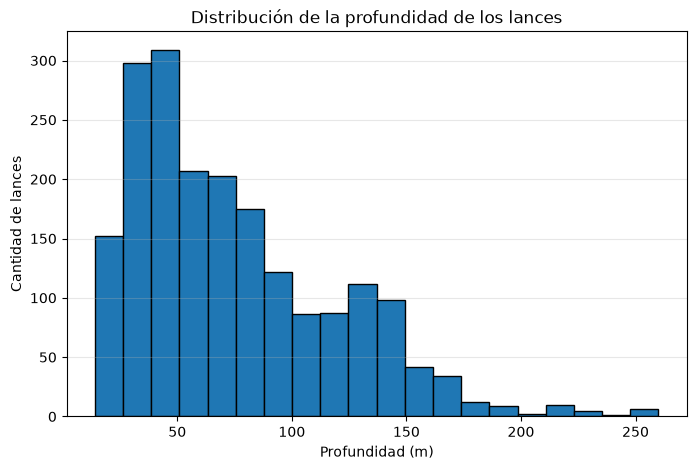

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_variables["Depth"], bins=20, edgecolor="black")

plt.title("Distribución de la profundidad de los lances")
plt.xlabel("Profundidad (m)")
plt.ylabel("Cantidad de lances")

plt.grid(axis="y", alpha=0.3)
plt.show()

### Interpretación de la distribución de profundidades

El histograma muestra que la mayor concentración de lances se encuentra en profundidades relativamente bajas, principalmente entre 25 y 90 metros.

La distribución presenta una asimetría hacia la derecha, con una disminución progresiva de la frecuencia en profundidades mayores. Esto coincide con una media de 74,94 metros, superior a la mediana de 65 metros.

También se observan algunos lances en profundidades superiores a 200 metros, que podrían considerarse valores poco frecuentes y requieren una revisión antes de determinar si son atípicos.

Este análisis describe las profundidades de los muestreos, pero todavía no permite establecer una relación con los registros de bacalao del Atlántico.

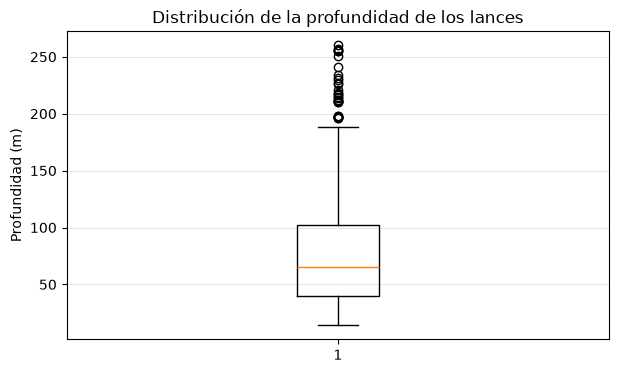

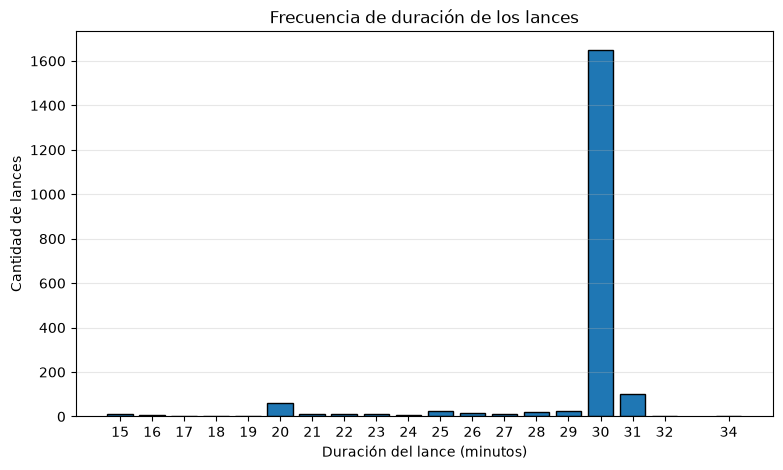

In [29]:
# Boxplot de profundidad
plt.figure(figsize=(7, 4))
plt.boxplot(df_variables["Depth"])

plt.title("Distribución de la profundidad de los lances")
plt.ylabel("Profundidad (m)")
plt.grid(axis="y", alpha=0.3)
plt.show()

# Gráfico de barras de duración
frecuencia_duracion = df_variables["HaulDur"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
plt.bar(
    frecuencia_duracion.index,
    frecuencia_duracion.values,
    edgecolor="black"
)

plt.title("Frecuencia de duración de los lances")
plt.xlabel("Duración del lance (minutos)")
plt.ylabel("Cantidad de lances")
plt.xticks(frecuencia_duracion.index)
plt.grid(axis="y", alpha=0.3)
plt.show()

### Interpretación de la profundidad y duración de los lances

El boxplot de profundidad muestra una mediana de 65 metros y un rango intercuartílico entre 40 y 102 metros. Se identifican posibles valores atípicos por encima de aproximadamente 195 metros, que no necesariamente representan errores y, por lo tanto, se conservarán para el análisis.

El gráfico de barras de duración evidencia que la mayoría de los lances se concentra en los 30 minutos, mientras que las demás duraciones presentan frecuencias considerablemente menores.

Estos resultados permiten reconocer diferencias en la variabilidad de ambas características. La profundidad presenta una mayor dispersión, mientras que la duración es relativamente uniforme. Posteriormente, se evaluará si estas variables aportan información relevante para la clasificación de los registros de bacalao del Atlántico.

In [30]:
# Identificar lances válidos con registros válidos de bacalao
bacalao_valido = df_bacalao[
    df_bacalao["SpecVal"] == "1"
][columnas_id].drop_duplicates()

# Crear dataset con los lances válidos
df_modelo = df_variables.merge(
    bacalao_valido.assign(presencia_bacalao=1),
    on=columnas_id,
    how="left",
    validate="one_to_one"
)

# Asignar clase 0 a lances sin registro válido de bacalao
df_modelo["presencia_bacalao"] = (
    df_modelo["presencia_bacalao"].fillna(0).astype(int)
)

# Verificar resultados
print("Total de observaciones:", len(df_modelo))
print("\nDistribución de la variable objetivo:")
print(df_modelo["presencia_bacalao"].value_counts())

print("\nDuplicados por lance:")
print(df_modelo.duplicated(subset=columnas_id).sum())

Total de observaciones: 1970

Distribución de la variable objetivo:
presencia_bacalao
1    1335
0     635
Name: count, dtype: int64

Duplicados por lance:
0


In [31]:
# Calcular el porcentaje de cada clase
porcentajes = (
    df_modelo["presencia_bacalao"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

print("\nPorcentaje de cada clase:")
print(porcentajes)


Porcentaje de cada clase:
presencia_bacalao
1    67.8
0    32.2
Name: proportion, dtype: float64


### Construcción de la variable objetivo

Se construyó la variable binaria `presencia_bacalao` a partir de los lances válidos y de los registros biológicos de *Gadus morhua*.

El conjunto resultante contiene **1.970 observaciones**, con una única fila por lance y sin duplicados según el identificador seleccionado.

Se identificaron **1.335 lances (67,8 %)** con registros válidos de bacalao, correspondientes a la clase 1, y **635 lances (32,2 %)** sin registros de la especie, correspondientes a la clase 0.

La clase 0 se asignó bajo el supuesto de que la falta de registro de bacalao en un lance válido, con información biológica disponible, representa una no detección documentada. Esta interpretación requiere considerar los criterios de registro de ICES-DATRAS y no implica que la especie esté ausente de la zona.

Se observa una mayor proporción de la clase 1, aspecto que deberá considerarse durante la evaluación de los modelos de clasificación.

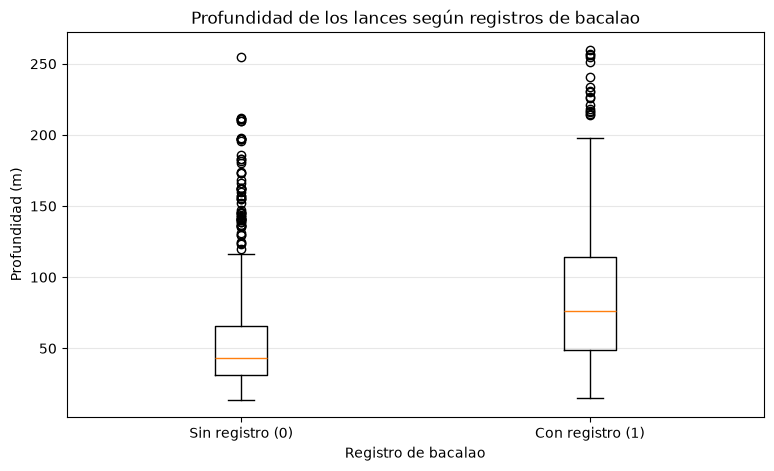

In [32]:
# Separar la profundidad según la variable objetivo
profundidad_sin = df_modelo.loc[
    df_modelo["presencia_bacalao"] == 0, "Depth"
]

profundidad_con = df_modelo.loc[
    df_modelo["presencia_bacalao"] == 1, "Depth"
]

# Crear el gráfico comparativo
plt.figure(figsize=(9, 5))

plt.boxplot(
    [profundidad_sin, profundidad_con],
    tick_labels=["Sin registro (0)", "Con registro (1)"]
)

plt.title("Profundidad de los lances según registros de bacalao")
plt.xlabel("Registro de bacalao")
plt.ylabel("Profundidad (m)")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Comparación de la profundidad según los registros de bacalao

El boxplot comparativo muestra diferencias en la distribución de profundidades entre los lances con y sin registros de *Gadus morhua*.

Los lances con registros de bacalao (clase 1) presentan una mediana de profundidad mayor, aproximadamente 76 metros, frente a los 43 metros de los lances sin registros (clase 0). Además, la clase 1 presenta una mayor dispersión.

Aunque existen diferencias entre ambas distribuciones, también se observa superposición de valores. Por lo tanto, la profundidad no permite distinguir por sí sola ambas clases.

Estos resultados sugieren que la profundidad podría ser una variable predictora relevante para la clasificación, aunque su utilidad deberá evaluarse posteriormente mediante los modelos de aprendizaje automático.

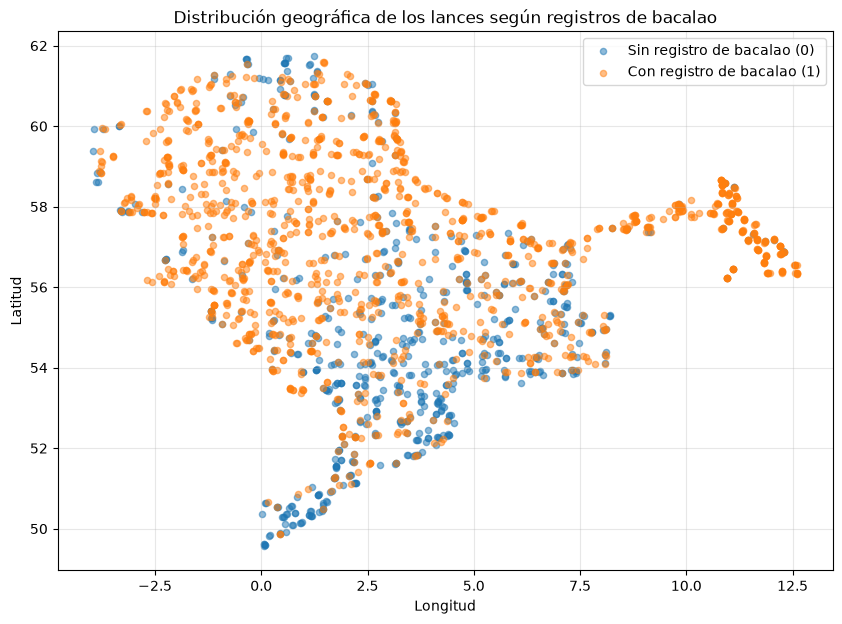

In [33]:
# Separar los lances según la variable objetivo
sin_bacalao = df_modelo[
    df_modelo["presencia_bacalao"] == 0
]

con_bacalao = df_modelo[
    df_modelo["presencia_bacalao"] == 1
]

# Crear gráfico de dispersión geográfica
plt.figure(figsize=(10, 7))

plt.scatter(
    sin_bacalao["ShootLong"],
    sin_bacalao["ShootLat"],
    alpha=0.5,
    s=20,
    label="Sin registro de bacalao (0)"
)

plt.scatter(
    con_bacalao["ShootLong"],
    con_bacalao["ShootLat"],
    alpha=0.5,
    s=20,
    label="Con registro de bacalao (1)"
)

plt.title("Distribución geográfica de los lances según registros de bacalao")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Distribución geográfica de los lances según los registros de bacalao

El gráfico muestra la ubicación de los lances con y sin registros de bacalao del Atlántico.

Se observa que los lances con registros de bacalao (clase 1) aparecen en gran parte del área estudiada, especialmente hacia el norte. En cambio, los lances sin registros (clase 0) se concentran relativamente más hacia el sur.

Aunque ambas clases comparten varias zonas, se observan diferencias que sugieren que la latitud y la longitud podrían ser útiles para los modelos de clasificación.

Este análisis representa los lances estudiados y no permite determinar la distribución real de la especie.

## Preparación del conjunto de datos para el modelado

Se seleccionan las variables predictoras, la variable objetivo y los identificadores de los lances para obtener un conjunto de datos organizado, que será utilizado en una etapa posterior para entrenar los modelos de clasificación.

In [34]:
# Seleccionar las columnas del dataset procesado
columnas_finales = (
    columnas_id
    + ["Depth", "ShootLat", "ShootLong", "HaulDur"]
    + ["presencia_bacalao"]
)

df_final = df_modelo[columnas_finales].copy()

# Verificar la estructura del dataset
print("Dimensiones del dataset:", df_final.shape)

print("\nTipos de datos:")
print(df_final.dtypes)

print("\nPrimeras cinco observaciones:")
display(df_final.head())

print("\nValores faltantes:")
print(df_final.isnull().sum())

Dimensiones del dataset: (1970, 13)

Tipos de datos:
Survey                   str
Quarter                  str
Year                     str
Country                  str
Ship                     str
Gear                     str
HaulNo                   str
StNo                     str
Depth                  int64
ShootLat             float64
ShootLong            float64
HaulDur                int64
presencia_bacalao      int64
dtype: object

Primeras cinco observaciones:


,Survey,Quarter,Year,Country,Ship,Gear,HaulNo,StNo,Depth,ShootLat,ShootLong,HaulDur,presencia_bacalao
0,NS-IBTS,1,2020,DK,26D4,GOV,1,6,35,56.6076,7.1445,30,0
1,NS-IBTS,1,2020,DK,26D4,GOV,2,8,45,56.5951,6.8874,30,0
2,NS-IBTS,1,2020,DK,26D4,GOV,3,10,33,56.3057,7.1858,30,1
3,NS-IBTS,1,2020,DK,26D4,GOV,4,11,36,56.3333,6.8544,30,0
4,NS-IBTS,1,2020,DK,26D4,GOV,5,19,73,56.7180,2.4918,30,1



Valores faltantes:
Survey               0
Quarter              0
Year                 0
Country              0
Ship                 0
Gear                 0
HaulNo               0
StNo                 0
Depth                0
ShootLat             0
ShootLong            0
HaulDur              0
presencia_bacalao    0
dtype: int64


### Verificación del conjunto de datos procesado

El conjunto de datos procesado contiene **1.970 observaciones y 13 columnas**, correspondientes a ocho identificadores, cuatro variables predictoras y una variable objetivo.

Se verificó que las variables predictoras son numéricas y que no existen valores faltantes. Además, cada fila representa un único lance válido.

El dataset queda organizado para su utilización en la siguiente etapa del proyecto, en la que se entrenarán y evaluarán los modelos de clasificación.

In [35]:
# Guardar el dataset procesado
ruta_procesado = Path("../data/processed/lances_bacalao_procesado.csv")

df_final.to_csv(ruta_procesado, index=False)

print("Archivo guardado en:", ruta_procesado)
print("Dimensiones:", df_final.shape)

Archivo guardado en: ..\data\processed\lances_bacalao_procesado.csv
Dimensiones: (1970, 13)
